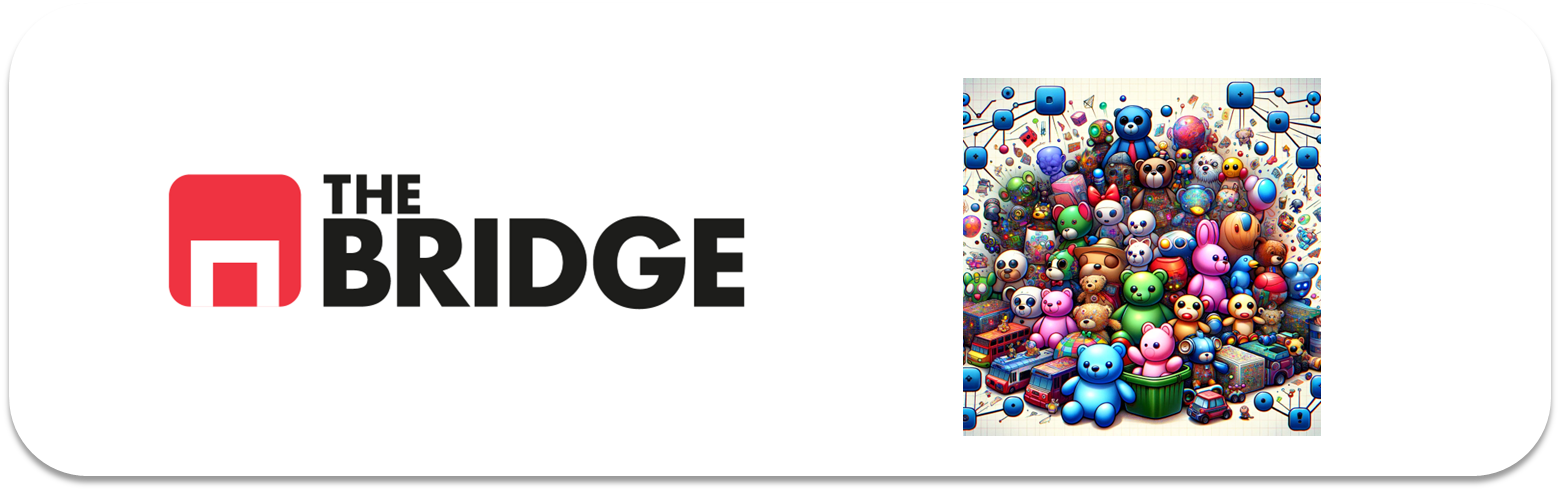

## Clustering No Jerárquico (I): K-Means


### Configuración

Para comenzar, ejecuta la siguiente celda que está únicamente dedicada a hacer los imports y configuraciones necesarias para poder funcionar correctamente con este notebook de apoyo.

In [1]:
# Imports comunes
import numpy as np
import os

# Para que los resultados de este notebook sean reproducibles
np.random.seed(42)

# Para que las figuras se vean bien
%matplotlib inline
import matplotlib as mpl
import matplotlib.pyplot as plt
mpl.rc('axes', labelsize=14)
mpl.rc('xtick', labelsize=12)
mpl.rc('ytick', labelsize=12)

# Ignoramos avisos irrelevantes (ver SciPy issue #5998)
import warnings
warnings.filterwarnings(action="ignore", message="^internal gelsd")

### Introducción: clasificación _vs_ agrupamiento (clustering)

$$*$$

In [2]:
from sklearn.datasets import load_iris

In [3]:
data = load_iris()
X = data.data
y = data.target
data.target_names

array(['setosa', 'versicolor', 'virginica'], dtype='<U10')

In [4]:
data['feature_names']

['sepal length (cm)',
 'sepal width (cm)',
 'petal length (cm)',
 'petal width (cm)']

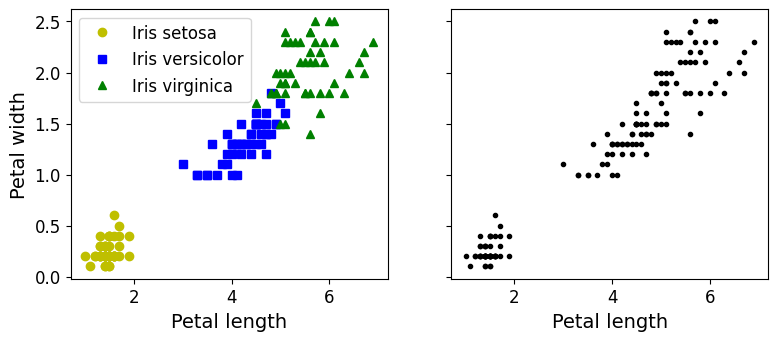

In [5]:
plt.figure(figsize=(9, 3.5))

plt.subplot(121)
plt.plot(X[y==0, 2], X[y==0, 3], "yo", label="Iris setosa")
plt.plot(X[y==1, 2], X[y==1, 3], "bs", label="Iris versicolor")
plt.plot(X[y==2, 2], X[y==2, 3], "g^", label="Iris virginica")
plt.xlabel("Petal length", fontsize=14)
plt.ylabel("Petal width", fontsize=14)
plt.legend(fontsize=12)

plt.subplot(122)
plt.scatter(X[:, 2], X[:, 3], c="k", marker=".")
plt.xlabel("Petal length", fontsize=14)
plt.tick_params(labelleft=False)


plt.show();

El dataset representado a la izquierda es el que usaríamos con un modelo supervisado para hacer la clasificación. El dataset representado a la derecha es, en cambio, el que tendríamos si no tuviéramos etiquetas y el que entregaríamos a un algoritmo no supervisado como K-Means. Es lo que vamos a hacer en la siguiente celda (ojo, es solo a título ilustrativo).

In [6]:
from sklearn.cluster import KMeans
k = 3
kmeans = KMeans(n_clusters=k, n_init=10, random_state=101)

y_pred = kmeans.fit_predict(X)

# Los números de cluster son arbitrarios: para poder comparar con las especies, traducimos cada cluster
# a la especie más frecuente entre sus flores (solo podemos hacerlo porque aquí sí tenemos el target)
mapping = np.array([np.bincount(y[y_pred == cluster_id]).argmax() for cluster_id in range(k)])
y_pred = mapping[y_pred]

Pintemos la salida y comparémosla al caso supervisado:

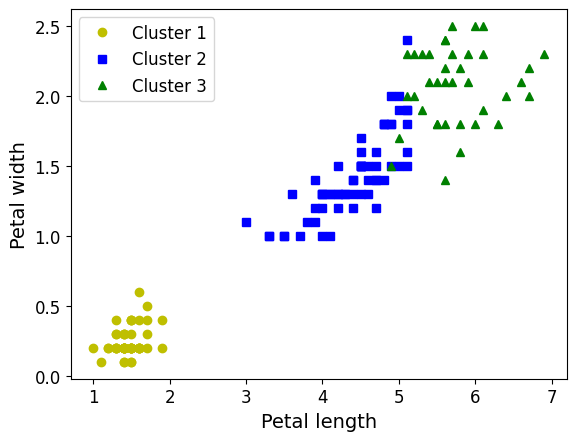

In [7]:
plt.plot(X[y_pred==0, 2], X[y_pred==0, 3], "yo", label="Cluster 1")
plt.plot(X[y_pred==1, 2], X[y_pred==1, 3], "bs", label="Cluster 2")
plt.plot(X[y_pred==2, 2], X[y_pred==2, 3], "g^", label="Cluster 3")
plt.xlabel("Petal length", fontsize=14)
plt.ylabel("Petal width", fontsize=14)
plt.legend(loc="upper left", fontsize=12)
plt.show()

No lo ha hecho nada mal. Pero ojo, antes de que se te haga un lío el cerebro, fíjate en las etiquetas de la leyenda. El algoritmo ha encontrado una agrupación con esos nombres, pero no puede decir si corresponden a un tipo u otro de flor: eso solo lo hacemos nosotros porque tenemos la versión "supervisada". En una realidad en la que no la tuviéramos, solo tendríamos esa clasificación (la de la imagen) y no su explicación. A partir de ahí trabajaríamos.

$$*$$

### K-Means

Un poco de "wikiconocimiento": El algoritmo k-means es un algoritmo sencillo capaz de hacer clustering de datos de manera muy rápida y eficiente, a menudo en solo unas pocas iteraciones. Fue propuesto por Stuart Lloyd en Bell Labs en 1957 pero solo se publicó fuera de la compañía en 1982.⁠ En 1965, Edward W. Forgy había publicado prácticamente el mismo algoritmo, por lo que a veces se conoce como el algoritmo Lloyd-Forgy.


Otro detalle es que tenemos que darle nosotros el número de agrupaciones o clusters que queremos, por lo que k se convierte en un hiperparámetro del algoritmo y tendremos que buscar una forma de optimizarlo (veremos varias técnicas más adelante en este notebook).

$$*$$

Para ir profundizando en el algoritmo, nos vamos a crear un dataset "sintético". Empecemos generando algunos "blobs" (manchurrones en mi traducción algeceriña):

In [8]:
from sklearn.datasets import make_blobs

Lo primero es generarnos unos "centroides". ¿Centro... qué?

#### **Centroide**

El centroide, dicho brutamente, es el centro de un cluster o agrupación: es el punto promedio (es decir, el que tiene como valores de sus features la media de cada feature). Aquí tienes una definición formal (pero para luego); ahora quédate con que lo que tenemos que dar es el "centro" de los manchurrones o clusters sintéticos que queremos crear.


**Definición formal:**
En geometría, el centroide o baricentro de una figura plana o un sólido es el punto en el que se podría considerar que está concentrada toda la masa de la figura para propósitos de cálculos de balance y momento. Matemáticamente, el centroide de un conjunto de puntos $(x_i, y_i, z_i)$ (piensa en x, y, z como las features) en un espacio tridimensional se calcula como el promedio aritmético de todas las coordenadas de los puntos. En términos de fórmula, si tenemos $n$ puntos, el centroide $(C_x, C_y, C_z)$ se calcula como:


$$C_x = \frac{1}{n}\sum_{i=1}^{n} x_i, \quad C_y = \frac{1}{n}\sum_{i=1}^{n} y_i, \quad C_z = \frac{1}{n}\sum_{i=1}^{n} z_i$$

En el contexto del aprendizaje automático y el análisis de clusters, un centroide es el punto que representa el centro de un cluster, calculado como el promedio de todas las observaciones (puntos de datos) en ese cluster. En algoritmos como K-means, los centroides son claves para determinar la pertenencia de los puntos de datos a diferentes grupos o clusters.

In [9]:
'''
Defino los centroides de mis datos sintéticos y su dispersión
Es simplemente para crear la muestra de datos
'''
blob_centroides = np.array([[0.2, 2.3],
                            [-1.5, 2.3],
                            [-2.8, 1.8],
                            [-2.8,2.8],
                            [-2.8, 1.3]])


Y para crear puntos en torno a esos centroides me defino una desviación estándar (ojo, nada de esto es fundamental: solo sirve para ilustrar el proceso).

In [10]:

blob_std = np.array([0.4, 0.3, 0.1, 0.1, 0.1])

In [11]:
X, y = make_blobs(n_samples = 2000,
                  centers = blob_centroides,
                  cluster_std = blob_std,
                  random_state = 15)


Ahora vamos a representarlos (y al tiempo definiremos una función que nos servirá posteriormente para visualizar los ejemplos):

In [12]:
def plot_clusters(X, y=None):
    plt.scatter(X[:, 0], X[:, 1], c=y, s=1)
    plt.xlabel("$x_1$", fontsize=14)
    plt.ylabel("$x_2$", fontsize=14, rotation=0)


Vamos a añadir el centroide de cada "manchurrón" para visualizar el concepto:

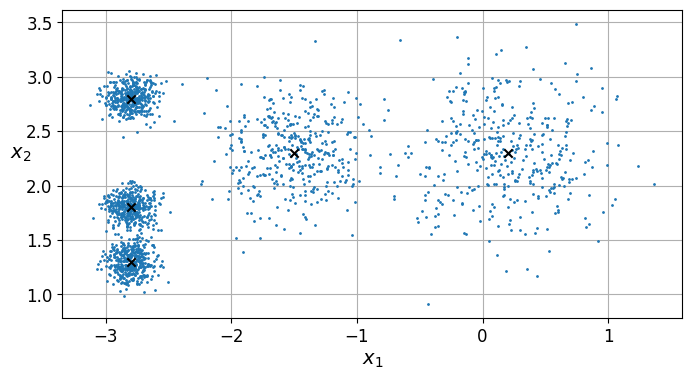

In [13]:
plt.figure(figsize=(8, 4))
plot_clusters(X)
plt.gca().set_axisbelow(True)
plt.grid()
for centroide in blob_centroides:
    plt.scatter(x = centroide[0], y = centroide[1], marker = "x", c = "black")
plt.show()




***

### Aplicación de K-Means: Fit and Predict (Ajuste y predicción)

Ahora vamos a entrenar un clusterizador K-Means en el conjunto de datos sintéticos de "manchurrones". Intentará encontrar el centro de cada mancha (el centroide) y asignar cada instancia a la mancha más cercana (es decir, a la mancha cuyo centroide esté a menor distancia de la instancia):

In [14]:
from sklearn.cluster import KMeans

In [15]:
# Comprobamos cómo divide K-Means en clusters
k = 5 # Lo tenemos que poner nosotros -> hiperparámetro
kmeans = KMeans(n_clusters = k,
                random_state =  4,
                n_init = 10) # n_init lo discutiremos más adelante; ahora no le prestes mucha atención

y_pred = kmeans.fit_predict(X) # Fit -> Obtén centroides, predict -> asigna cluster (de los k posibles)
y_pred

# Podemos hacerlo en dos pasos:
# kmeans.fit(X)
# y_pred = kmeans.predict(X)

array([4, 4, 3, ..., 0, 3, 4])

En $y_{pred}$ tenemos la asignación de clusters para cada una de las instancias de nuestro dataset de train (aquí no hay "test", no es supervisado, ojo). Pero eso no quiere decir que a partir de ahora no podamos "clusterizar" (asignar a un clúster) cualquier dato nuevo que nos venga:

In [16]:
kmeans.predict([[-2,2.5]]) # Doble corchete porque espera un array de instancias 

array([3])

[Un momento: ¿no habíamos dicho que esto no es un clasificador? No lo es, al menos no como un clasificador supervisado. Ha asignado la instancia con valores de features -2 y 2.5 a un cluster, pero no tenemos forma de saber si esa asignación es "correcta": en un problema no supervisado no hay clases correctas de partida (si las tuviéramos, el problema sería supervisado). Otra cosa es que, viendo el resultado del clustering, nosotros demos sentido a los grupos y los usemos, por ejemplo, para etiquetar.]

Volviendo a nuestro ejemplo, cada instancia fue asignada a uno de los 5 clusters:

In [17]:
print(y_pred)
print(y_pred is kmeans.labels_)

[4 4 3 ... 0 3 4]
True


Y los siguientes 5 _centroides_ (es decir, centros de cluster) fueron estimados:

In [18]:
kmeans.cluster_centers_

array([[-2.79769606,  1.29691863],
       [-2.79486621,  2.80634881],
       [ 0.20194078,  2.28688569],
       [-1.48596019,  2.3145888 ],
       [-2.80056785,  1.80212092]])

En este caso, y solo en este, en el que hemos creado el dataset artificialmente, podemos comparar los centroides estimados con los reales:

In [19]:
blob_centroides

array([[ 0.2,  2.3],
       [-1.5,  2.3],
       [-2.8,  1.8],
       [-2.8,  2.8],
       [-2.8,  1.3]])

No está mal, ¿verdad? Eso sí, no los compares fila a fila: el algoritmo no sabe en qué orden le dimos los centroides, así que el primer centroide estimado no tiene por qué corresponder al primero que definimos. Busca para cada centroide estimado el real más parecido.

El índice de cluster que se asigna depende del orden de obtención de los centroides. En nuestro caso, los puntos más cercanos al primer centroide estimado recibirán la etiqueta 0.

In [20]:
'''
Esta etiqueta es el índice del cluster. Sirve para relacionarlo con
kmeans.cluster_centers_. El primer centroide corresponde a la etiqueta 0
'''
for i in range(5):
    print(f"X1={X[i,0]}, X2 = {X[i,1]} -> label: {kmeans.labels_[i]}")

X1=-2.8271528107048978, X2 = 1.5902320438691129 -> label: 4
X1=-2.8629761247307077, X2 = 1.7191437228470188 -> label: 4
X1=-1.2006199614308943, X2 = 2.6042609257463063 -> label: 3
X1=-0.14429693356516166, X2 = 2.2709398245422157 -> label: 2
X1=0.232391361111047, X2 = 2.132823714575191 -> label: 2


Y ahora pintemos las agrupaciones (ojo al truco con la función que nos creamos antes):

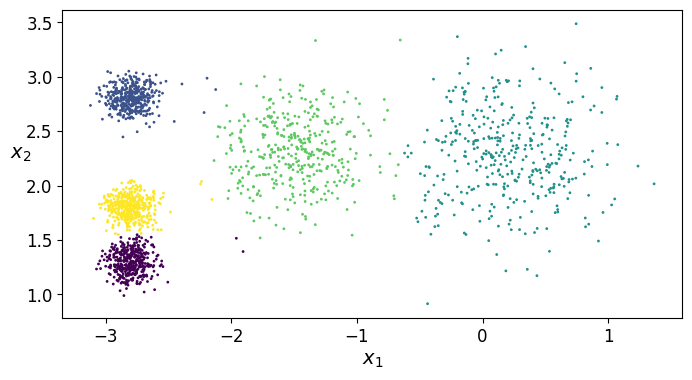

In [21]:
plt.figure(figsize=(8, 4))
plot_clusters(X, y = kmeans.predict(X)) # y realmente es el color, no el eje y
plt.show()

No tiene mala pinta, pero, claro, recuerda que en la vida real no tendremos la referencia de qué cluster o agrupación tiene sentido.

***

### Límites de decisión

Vamos a trazar los límites de decisión del modelo. Esto nos dará lo que se denomina un *diagrama de Voronoi*. Vamos a utilizar las siguientes funciones, que no son fundamentales para tu aprendizaje:

In [22]:
def plot_data(X):
    plt.plot(X[:, 0], X[:, 1], 'k.', markersize=2)

def plot_centroids(centroids, weights=None, circle_color='w', cross_color='b'):
    if weights is not None:
        centroids = centroids[weights > weights.max() / 10]
    plt.scatter(centroids[:, 0], centroids[:, 1],
                marker='o', s=30, linewidths=8,
                color=circle_color, zorder=10, alpha=0.9)
    plt.scatter(centroids[:, 0], centroids[:, 1],
                marker='x', s=15, linewidths=20,
                color=cross_color, zorder=11, alpha=1)

def plot_decision_boundaries(clusterer, X, resolution=1000, show_centroids=True,
                             show_xlabels=True, show_ylabels=True):
    mins = X.min(axis=0) - 0.1
    maxs = X.max(axis=0) + 0.1
    xx, yy = np.meshgrid(np.linspace(mins[0], maxs[0], resolution),
                         np.linspace(mins[1], maxs[1], resolution))
    Z = clusterer.predict(np.c_[xx.ravel(), yy.ravel()])
    Z = Z.reshape(xx.shape)

    plt.contourf(Z, extent=(mins[0], maxs[0], mins[1], maxs[1]),
                cmap="Pastel2")
    plt.contour(Z, extent=(mins[0], maxs[0], mins[1], maxs[1]),
                linewidths=1, colors='k')
    plot_data(X)
    if show_centroids:
        plot_centroids(clusterer.cluster_centers_)

    if show_xlabels:
        plt.xlabel("$x_1$", fontsize=14)
    else:
        plt.tick_params(labelbottom=False)
    if show_ylabels:
        plt.ylabel("$x_2$", fontsize=14, rotation=0)
    else:
        plt.tick_params(labelleft=False)

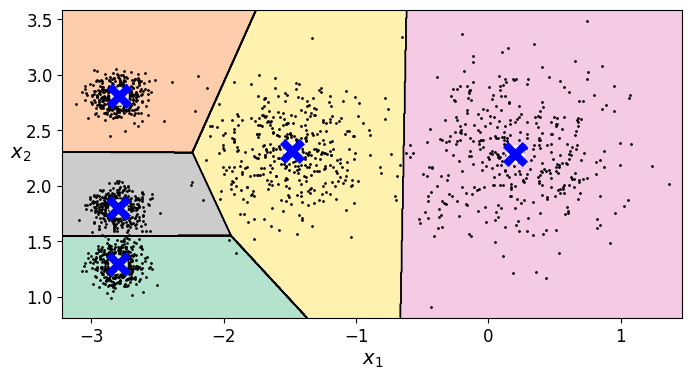

In [23]:
plt.figure(figsize=(8, 4))
plot_decision_boundaries(kmeans, X)
plt.show()

¡No está mal! Es probable que algunas de las instancias cercanas a los bordes hayan sido asignadas al clúster incorrecto, pero en general parece bastante bueno. ("Bueno" aquí quiere decir que es el clustering que haríamos nosotros a ojo, solo que K-Means nos simplifica la tarea: una aplicación de automatización interesante, sin duda.)

### Hard Clustering _vs_ Soft Clustering

En lugar de elegir arbitrariamente el clúster más cercano para cada instancia, lo cual se denomina *hard clustering*, podría ser mejor medir la distancia de cada instancia a los 5 centroides y luego nosotros implementar un mecanismo de decisión alternativo. Esto es lo que hace el método `transform()`: devolvernos las distancias de cada instancia a los centroides.

In [24]:
'''
Como hard voting vs soft voting en los ensembles
'''
# Supongamos que nos llegan nuevos datos:
X_new = np.array([[0, 2], [3, 2], [-3, 3], [-3, 2.5]])


*Hard clustering*: nos da el cluster cuyo centroide está más cerca de la instancia.

In [25]:
kmeans.predict(X_new)

array([2, 2, 1, 1])

*Soft clustering*: nos da las distancias a cada centroide, y podemos implementar un mecanismo diferente.

In [26]:
'''
La distancia de cada punto a predecir a cada centroide. Puede ser una buena manera
de reducir el dataset a k dimensiones.
'''
kmeans.transform(X_new)

array([[2.88468831, 2.90886155, 0.35083255, 1.51889559, 2.80754989],
       [5.84017149, 5.85069849, 2.812728  , 4.49697731, 5.80394207],
       [1.71505482, 0.28210043, 3.28038973, 1.6619582 , 1.21436711],
       [1.219972  , 0.36868613, 3.20902516, 1.5253504 , 0.72581567]])

Puedes verificar que esta es, de hecho, la distancia euclidiana entre cada instancia y cada centroide:

In [27]:
'''
np.tile y el reshape repiten X_new k veces (una por centroide), para restar cada punto de cada centro. Luego se calcula la norma,
que es la distancia euclídea
'''
np.linalg.norm(np.tile(X_new, (1, k)).reshape(-1, k, 2) - kmeans.cluster_centers_, axis=2)

array([[2.88468831, 2.90886155, 0.35083255, 1.51889559, 2.80754989],
       [5.84017149, 5.85069849, 2.812728  , 4.49697731, 5.80394207],
       [1.71505482, 0.28210043, 3.28038973, 1.6619582 , 1.21436711],
       [1.219972  , 0.36868613, 3.20902516, 1.5253504 , 0.72581567]])

***

### Algoritmo K-Means

**Funcionamiento teórico**

El algoritmo K-Means es uno de los algoritmos de agrupamiento más rápidos, pero también uno de los más simples:

* Primero inicializa $k$ centroides de forma aleatoria: se eligen de forma aleatoria $k$ instancias distintas del conjunto de datos y se colocan los centroides en sus ubicaciones. [Es decir, se escogen k instancias y esas son los primeros centroides.]
* Ahora se asignan todas las instancias al cluster que corresponda al centroide del que están más cerca.
* Hecha esta elección, se recalculan los centroides de cada cluster (es decir, se hace el promedio de las features de las instancias de cada cluster y ese es el nuevo centroide) y se vuelve a empezar. Es decir:
* Repetir hasta la convergencia (es decir, hasta que los centroides dejen de moverse; en general, esto implica que los centroides nuevos no distan más de un valor de tolerancia del centroide anterior o bien hasta un número determinado de repeticiones del recálculo de centroides):
    * Asignar cada instancia al centroide más cercano.
    * Actualizar los centroides para que sean la media de las instancias que están asignadas a ellos.

Realmente, la clase `KMeans` aplica por defecto una versión optimizada del algoritmo anterior (con una inicialización más inteligente, llamada k-means++). Para obtener el algoritmo original de K-Means (solo con fines educativos), debes establecer `init="random"` y `n_init=1`. Estos hiperparámetros se explicarán a continuación.

Vamos a ejecutar el algoritmo K-Means durante 1, 2 y 3 iteraciones, para ver cómo se mueven los centroides:

In [28]:
'''
init: varias maneras de inicializar los clusters, por defecto una más eficiente que random. Random -> es elección aleatoria de los centroides.
n_init: número de veces que se repite el algoritmo con diferentes centroides de inicio. 
        Luego se escoge la clusterización o la repetición con la mejor puntuación en una 
        métrica que veremos un poco más adelante, la inercia o inertia.
max_iter: número de veces que recalculará centroides
'''
kmeans_iter1 = KMeans(n_clusters = 5, 
                      init = 'random', 
                      n_init = 1, 
                      max_iter = 1, # 
                      random_state = 24)


kmeans_iter2 = KMeans(n_clusters = 5, 
                      init = 'random', 
                      n_init = 1, 
                      max_iter = 2, 
                      random_state = 24)


kmeans_iter3 = KMeans(n_clusters = 5, 
                      init = 'random', 
                      n_init = 1, 
                      max_iter = 3, 
                      random_state = 24)


kmeans_iter1.fit(X)
kmeans_iter2.fit(X)
kmeans_iter3.fit(X)

,"n_clusters n_clusters: int, default=8The number of clusters to form as well as the number ofcentroids to generate.For an example of how to choose an optimal value for `n_clusters` refer to:ref:`sphx_glr_auto_examples_cluster_plot_kmeans_silhouette_analysis.py`.",5
,"init init: {'k-means++', 'random'}, callable or array-like of shape (n_clusters, n_features), default='k-means++'Method for initialization:* 'k-means++' : selects initial cluster centroids using sampling based on an empirical probability distribution of the points' contribution to the overall inertia. This technique speeds up convergence. The algorithm implemented is ""greedy k-means++"". It differs from the vanilla k-means++ by making several trials at each sampling step and choosing the best centroid among them.* 'random': choose `n_clusters` observations (rows) at random from data for the initial centroids.* If an array is passed, it should be of shape (n_clusters, n_features) and gives the initial centers.* If a callable is passed, it should take arguments X, n_clusters and a random state and return an initialization.For an example of how to use the different `init` strategies, see:ref:`sphx_glr_auto_examples_cluster_plot_kmeans_digits.py`.For an evaluation of the impact of initialization, see the example:ref:`sphx_glr_auto_examples_cluster_plot_kmeans_stability_low_dim_dense.py`.",'random'
,"n_init n_init: 'auto' or int, default='auto'Number of times the k-means algorithm is run with different centroidseeds. The final results is the best output of `n_init` consecutive runsin terms of inertia. Several runs are recommended for sparsehigh-dimensional problems (see :ref:`kmeans_sparse_high_dim`).When `n_init='auto'`, the number of runs depends on the value of init:10 if using `init='random'` or `init` is a callable;1 if using `init='k-means++'` or `init` is an array-like... versionadded:: 1.2 Added 'auto' option for `n_init`... versionchanged:: 1.4 Default value for `n_init` changed to `'auto'`.",1
,"max_iter max_iter: int, default=300Maximum number of iterations of the k-means algorithm for asingle run.",3
,"random_state random_state: int, RandomState instance or None, default=NoneDetermines random number generation for centroid initialization. Usean int to make the randomness deterministic.See :term:`Glossary <random_state>`.",24
,"tol tol: float, default=1e-4Relative tolerance with regards to Frobenius norm of the differencein the cluster centers of two consecutive iterations to declareconvergence.",0.0001
,"verbose verbose: int, default=0Verbosity mode.",0
,"copy_x copy_x: bool, default=TrueWhen pre-computing distances it is more numerically accurate to centerthe data first. If copy_x is True (default), then the original data isnot modified. If False, the original data is modified, and put backbefore the function returns, but small numerical differences may beintroduced by subtracting and then adding the data mean. Note that ifthe original data is not C-contiguous, a copy will be made even ifcopy_x is False. If the original data is sparse, but not in CSR format,a copy will be made even if copy_x is False.",True
,"algorithm algorithm: {""lloyd"", ""elkan""}, default=""lloyd""K-means algorithm to use. The classical EM-style algorithm is `""lloyd""`.The `""elkan""` variation can be more efficient on some datasets withwell-defined clusters, by using the triangle inequality. However it'smore memory intensive due to the allocation of an extra array of shape`(n_samples, n_clusters)`... versionchanged:: 0.18 Added Elkan algorithm.. versionchanged:: 1.1 Renamed ""full"" to ""lloyd"", and deprecated ""auto"" and ""full"". Changed ""auto"" to use ""lloyd"" instead of ""elkan"".",'lloyd'
Name,Type,Value
"cluster_centers_ cluster_centers_: ndarray of shape (n_clusters, n_features)Coordinates of cluster centers. If the algorithm stops before fullyconverging (see ``tol`` and ``max_iter``), these will not beconsistent with ``labels_``.","ndarray[float64](5, 2)","[[-2.82, 1.

Creamos tres K-Means y vemos qué ocurre con los centroides (fíjate en que, al utilizar la misma semilla, cada modelo/algoritmo escogerá los mismos centroides de partida). Así podremos ver los centroides tras la primera selección, la segunda y la tercera.

Y vamos a pintar cómo se mueven los centroides y, por tanto, las zonas de decisión:

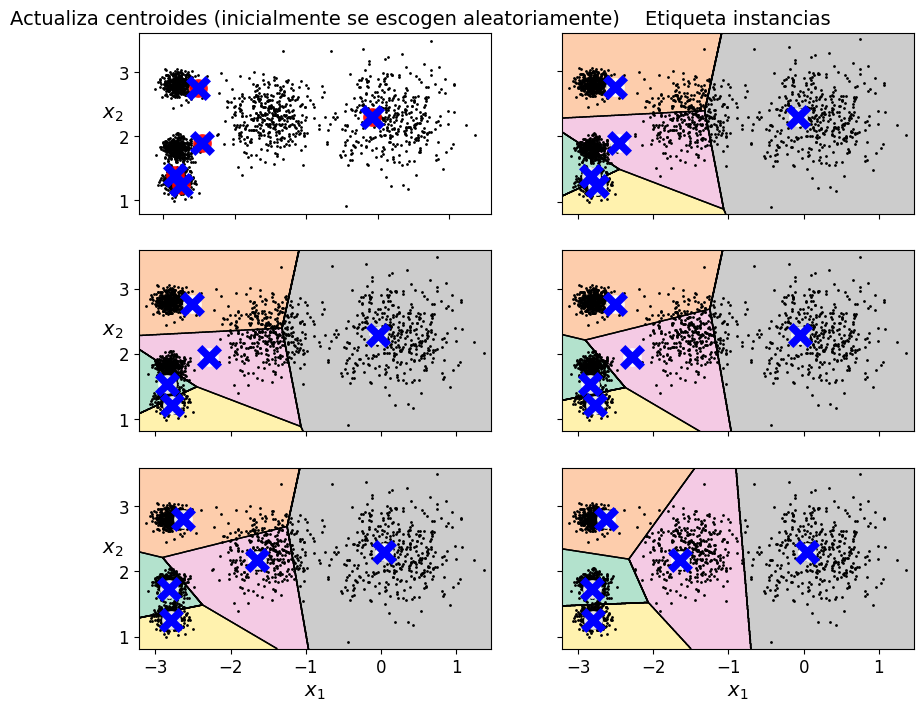

In [29]:
plt.figure(figsize=(10, 8))

# Pintamos los centroides del primer modelo que solo ha hecho una iteración, es decir, los centroides elegidos aleatoriamente (no se han llegado a actualizar)
plt.subplot(321) # 321 -> 3 filas, 2 columnas, elemento 1 (fila 0, columna 0)
plot_data(X)
plot_centroids(kmeans_iter1.cluster_centers_, circle_color='r', cross_color='b')
plt.ylabel("$x_2$", fontsize=14, rotation=0)
plt.tick_params(labelbottom=False)
plt.title("Actualiza centroides (inicialmente se escogen aleatoriamente)", fontsize=14)

# Pintamos los boundaries, es decir, cómo "etiquetamos" las instancias
plt.subplot(322) # 322 -> 3 filas, 2 columnas, elemento 2 (fila 0, columna 1)
plot_decision_boundaries(kmeans_iter1, X, show_xlabels=False, show_ylabels=False)
plt.title("Etiqueta instancias", fontsize=14)

# Sobre la elección anterior, pintamos los centroides de la segunda iteración, es decir, los centroides recalculados
plt.subplot(323)
plot_decision_boundaries(kmeans_iter1, X, show_centroids=False, show_xlabels=False)
plot_centroids(kmeans_iter2.cluster_centers_)

# pintamos las nuevas zonas de elección
plt.subplot(324)
plot_decision_boundaries(kmeans_iter2, X, show_xlabels=False, show_ylabels=False)

# pintamos los centroides de la tercera iteración
plt.subplot(325)
plot_decision_boundaries(kmeans_iter2, X, show_centroids=False)
plot_centroids(kmeans_iter3.cluster_centers_)

# pintamos la clusterización de la tercera iteración
plt.subplot(326)
plot_decision_boundaries(kmeans_iter3, X, show_ylabels=False)


plt.show()

### Variabilidad de K-Means

En el algoritmo original de K-Means, los centroides simplemente se inicializan al azar, y el algoritmo se ejecuta una única vez, mejorando los centroides iteración a iteración como acabamos de ver.

Sin embargo, un problema importante con este enfoque es que si se ejecuta K-Means varias veces (o con diferentes semillas aleatorias), puede converger a soluciones muy diferentes, como se puede ver a continuación:

In [30]:
'''
Ejemplo de ejecución de K-Means con dos semillas diferentes. Debido al inicio aleatorio, convergerá de manera diferente.
Lo solucionamos con la inercia: inicializamos varias veces y nos quedamos con la ejecución de mejor inercia, una métrica que veremos un poco más adelante.
'''
def plot_clusterer_comparison(clusterer1, clusterer2, X, title1=None, title2=None):
    clusterer1.fit(X)
    clusterer2.fit(X)

    plt.figure(figsize=(10, 3.2))

    plt.subplot(121)
    plot_decision_boundaries(clusterer1, X)
    if title1:
        plt.title(title1, fontsize=14)

    plt.subplot(122)
    plot_decision_boundaries(clusterer2, X, show_ylabels=False)
    if title2:
        plt.title(title2, fontsize=14)

Creamos dos clusterings que se van a ejecutar completos pero empezando con centroides diferentes y vamos a ver cómo agrupa cada uno por separado.

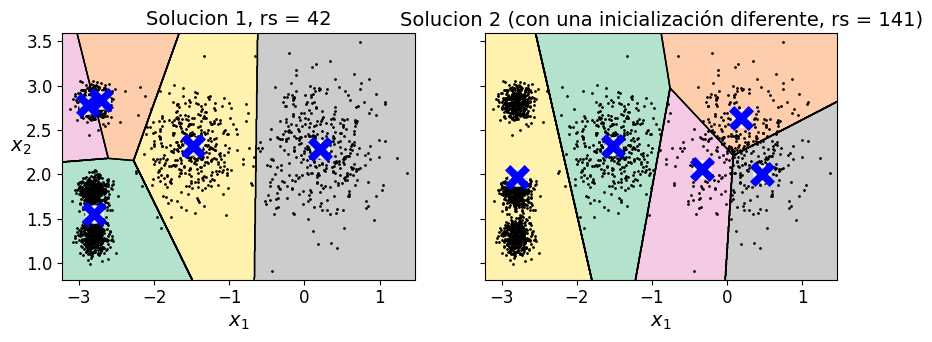

In [31]:
kmeans_rnd_init1 = KMeans(n_clusters = 5, init = 'random', n_init=1, random_state = 42)
kmeans_rnd_init2 = KMeans(n_clusters = 5, init = 'random', n_init=1, random_state = 141)

plot_clusterer_comparison(kmeans_rnd_init1, kmeans_rnd_init2, X,
                          "Solucion 1, rs = 42", "Solucion 2 (con una inicialización diferente, rs = 141)")


plt.show()

¿Cuál deberíamos considerar mejor? Para ello veremos a continuación la métrica que aplica internamente K-Means para decidir, entre varias agrupaciones posibles, cuál es mejor.

***

### Inercia (Inertia)

Para seleccionar el mejor modelo, necesitaremos una forma de evaluar el rendimiento de un modelo de K-Means. Desafortunadamente, la agrupación es una tarea no supervisada, por lo que no tenemos targets y no podemos emplear algo como la precision o el recall.  

Pero al menos podemos medir la distancia entre cada instancia y su centroide y a partir de ahí sacar una métrica. Esta es la idea detrás de la métrica de _inercia_ o *inertia* (en inglés):

In [32]:
'''
La suma de las distancias al cuadrado de cada punto a cada centroide
Cuanto más baja la inercia, más cerca están los puntos de los centroides y, en teoría, la agrupación es "mejor" 
'''
kmeans_rnd_init1.inertia_

266.605979546967

In [33]:
kmeans_rnd_init2.inertia_

625.742130188727

Como puedes verificar fácilmente, la inercia es la suma de las distancias al cuadrado entre cada instancia de entrenamiento y su centroide más cercano:

In [34]:
X_dist = kmeans_rnd_init1.transform(X) # Obtenemos la distancia de cada instancia a los centroides
sum(X_dist[np.arange(len(X_dist)), kmeans_rnd_init1.labels_]**2) # Mira qué forma tan "ingeniosa" de calcular la inercia

266.60597954696766

Otra forma de calcularla (aplicada al segundo K-Means):

In [35]:
inercia = 0
for indice,vector in enumerate(X): # Vamos a recorrer todas las instancias, en concreto sus clusters asignados
    clase_asignada = kmeans_rnd_init2.labels_[indice]
    distancia = np.linalg.norm(vector - kmeans_rnd_init2.cluster_centers_[clase_asignada])
    distancia_al_cuadrado = distancia**2
    inercia += distancia_al_cuadrado
print(inercia)

625.7421301887265


Considerando esta métrica (cuanto menos inercia, mejor), el primer clustering es mejor que el segundo (visualmente también lo parece).

Además, no vas a tener que hacer cálculos: tienes el atributo `inertia_` y el método `score()` devuelve la inercia negativa. ¿Por qué negativa? Bueno, es porque el método `score()` de un predictor siempre debe respetar la regla "_mientras más grande, mejor_".

In [36]:
# Objetivo: minimizar la inercia
kmeans_rnd_init1.score(X)

-266.605979546967

Muy bien, y esto ¿de qué nos sirve? Pues para aliviar el problema de depender de unos centroides iniciales aleatorios.

### Múltiples inicializaciones

Un enfoque para resolver el problema de variabilidad es simplemente ejecutar el algoritmo K-Means varias veces con diferentes inicializaciones aleatorias, y seleccionar la solución que minimice la inercia. Por ejemplo, aquí están las inercias de los dos modelos "malos" mostrados en la figura anterior:

In [37]:
kmeans_rnd_init1.inertia_

266.605979546967

In [38]:
kmeans_rnd_init2.inertia_

625.742130188727

Y la inercia del primer modelo, que nos gustaba:

In [39]:
kmeans.inertia_

218.53578971917145

Como puedes ver, tienen una inercia mayor que el primer modelo "bueno" que entrenamos, lo que significa que probablemente son peores.

Cuando estableces el hiperparámetro `n_init`, Scikit-Learn ejecuta el algoritmo original `n_init` veces, y selecciona la solución que minimiza la inercia.

In [40]:
kmeans_rnd_10_init = KMeans(n_clusters = 5, init = 'random', n_init=10, random_state = 29)
kmeans_rnd_10_init.fit(X)

,"n_clusters n_clusters: int, default=8The number of clusters to form as well as the number ofcentroids to generate.For an example of how to choose an optimal value for `n_clusters` refer to:ref:`sphx_glr_auto_examples_cluster_plot_kmeans_silhouette_analysis.py`.",5
,"init init: {'k-means++', 'random'}, callable or array-like of shape (n_clusters, n_features), default='k-means++'Method for initialization:* 'k-means++' : selects initial cluster centroids using sampling based on an empirical probability distribution of the points' contribution to the overall inertia. This technique speeds up convergence. The algorithm implemented is ""greedy k-means++"". It differs from the vanilla k-means++ by making several trials at each sampling step and choosing the best centroid among them.* 'random': choose `n_clusters` observations (rows) at random from data for the initial centroids.* If an array is passed, it should be of shape (n_clusters, n_features) and gives the initial centers.* If a callable is passed, it should take arguments X, n_clusters and a random state and return an initialization.For an example of how to use the different `init` strategies, see:ref:`sphx_glr_auto_examples_cluster_plot_kmeans_digits.py`.For an evaluation of the impact of initialization, see the example:ref:`sphx_glr_auto_examples_cluster_plot_kmeans_stability_low_dim_dense.py`.",'random'
,"n_init n_init: 'auto' or int, default='auto'Number of times the k-means algorithm is run with different centroidseeds. The final results is the best output of `n_init` consecutive runsin terms of inertia. Several runs are recommended for sparsehigh-dimensional problems (see :ref:`kmeans_sparse_high_dim`).When `n_init='auto'`, the number of runs depends on the value of init:10 if using `init='random'` or `init` is a callable;1 if using `init='k-means++'` or `init` is an array-like... versionadded:: 1.2 Added 'auto' option for `n_init`... versionchanged:: 1.4 Default value for `n_init` changed to `'auto'`.",10
,"random_state random_state: int, RandomState instance or None, default=NoneDetermines random number generation for centroid initialization. Usean int to make the randomness deterministic.See :term:`Glossary <random_state>`.",29
,"max_iter max_iter: int, default=300Maximum number of iterations of the k-means algorithm for asingle run.",300
,"tol tol: float, default=1e-4Relative tolerance with regards to Frobenius norm of the differencein the cluster centers of two consecutive iterations to declareconvergence.",0.0001
,"verbose verbose: int, default=0Verbosity mode.",0
,"copy_x copy_x: bool, default=TrueWhen pre-computing distances it is more numerically accurate to centerthe data first. If copy_x is True (default), then the original data isnot modified. If False, the original data is modified, and put backbefore the function returns, but small numerical differences may beintroduced by subtracting and then adding the data mean. Note that ifthe original data is not C-contiguous, a copy will be made even ifcopy_x is False. If the original data is sparse, but not in CSR format,a copy will be made even if copy_x is False.",True
,"algorithm algorithm: {""lloyd"", ""elkan""}, default=""lloyd""K-means algorithm to use. The classical EM-style algorithm is `""lloyd""`.The `""elkan""` variation can be more efficient on some datasets withwell-defined clusters, by using the triangle inequality. However it'smore memory intensive due to the allocation of an extra array of shape`(n_samples, n_clusters)`... versionchanged:: 0.18 Added Elkan algorithm.. versionchanged:: 1.1 Renamed ""full"" to ""lloyd"", and deprecated ""auto"" and ""full"". Changed ""auto"" to use ""lloyd"" instead of ""elkan"".",'lloyd'
Name,Type,Value
"cluster_centers_ cluster_centers_: ndarray of shape (n_clusters, n_features)Coordinates of cluster centers. If the algorithm stops before fullyconverging (see ``tol`` and ``max_iter``), these will not beconsistent with ``labels_``.","ndarray[float64](5, 2)","[[-1.49,

Como puedes ver, terminamos con el modelo inicial, que ciertamente es la solución óptima de K-Means (al menos en términos de inercia, y asumiendo $k=5$).

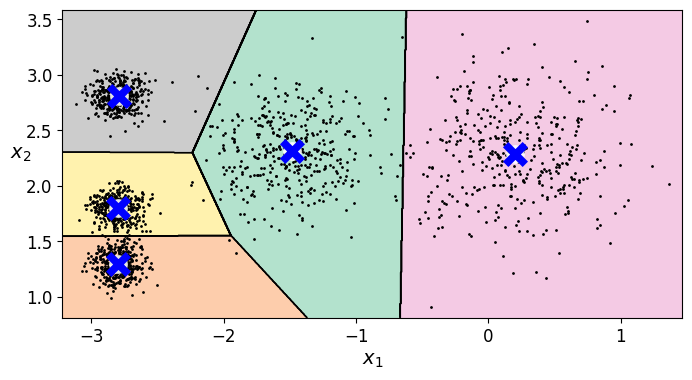

In [41]:
plt.figure(figsize=(8, 4))
plot_decision_boundaries(kmeans_rnd_10_init, X)
plt.show()

Pero la inercia no solo sirve para que internamente el algoritmo decida cuál de todos sus "intentos" es el mejor, sino que también nos puede servir para encontrar el valor de k más interesante (recuerda que es un hiperparámetro).

***

### Encontrar el número óptimo de clústeres

#### Mediante la inercia

Si la inercia es nuestra métrica de bondad de un modelo de clustering, parece claro que una forma de encontrar el $k$ óptimo sería ir probando valores y quedarnos con el que dé lugar a un agrupamiento con la inercia menor... Pero, antes de aferrarnos a ello, veamos qué sucedería si el número de clústeres se estableciera en un valor inferior o superior a 5:

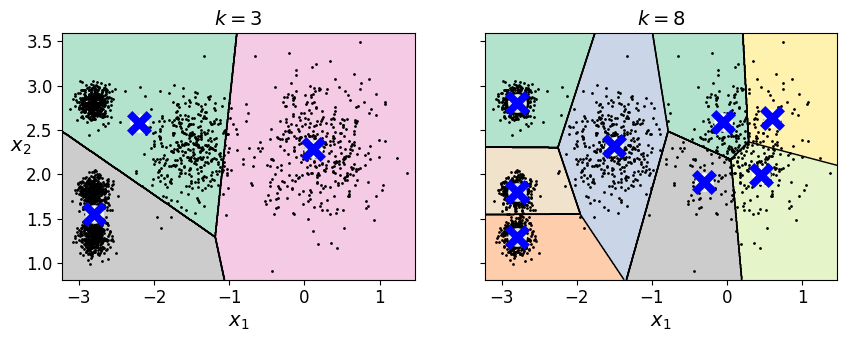

In [42]:
'''
Conseguir un modelo con la inercia baja, no quiere decir que sea el mejor.
Quizá otra cantidad de clusters sea más apropiada
Cuanto mayor es k, menor es la inercia, pero ¿hasta cuándo aumentamos k? -> Elbow
'''
kmeans_k3 = KMeans(n_clusters=3, random_state=42)
kmeans_k8 = KMeans(n_clusters=8, random_state=42)

plot_clusterer_comparison(kmeans_k3, kmeans_k8, X, "$k=3$", "$k=8$")
plt.show()

No parecen muy buenos. Veamos sus inercias:

In [43]:
kmeans_k3.inertia_

645.1463798380544

In [44]:
kmeans_k8.inertia_

136.63492752465578

No, no podemos simplemente tomar el valor de $k$ que minimiza la inercia, ya que esta sigue disminuyendo a medida que incrementamos $k$. De hecho, mientras más grupos haya, cada instancia estará más cerca de su centroide más cercano, y por lo tanto la inercia será menor. Sin embargo, podemos pintar la inercia como una función de $k$ y analizar la curva resultante:

In [45]:
kmeans_per_k = [KMeans(n_clusters=k, random_state= 42, n_init = 25).fit(X)
                for k in range(1, 10)]
inertias = [model.inertia_ for model in kmeans_per_k]

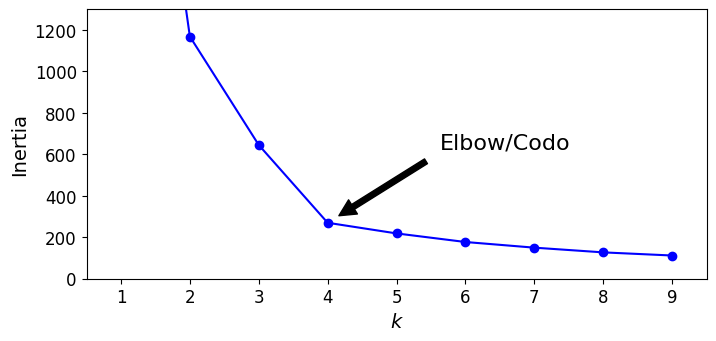

In [46]:
plt.figure(figsize=(8, 3.5))
plt.plot(range(1, 10), inertias, "bo-")
plt.xlabel("$k$", fontsize=14)
plt.ylabel("Inertia", fontsize=14)
plt.annotate('Elbow/Codo',
             xy=(4, inertias[3]),
             xytext=(0.55, 0.55),
             textcoords='figure fraction',
             fontsize=16,
             arrowprops=dict(facecolor='black', shrink=0.1)
            )
plt.axis([0.5, 9.5, 0, 1300])
plt.show()

Como puedes ver, hay un codo en $k=4$, lo que significa que menos clusters que eso sería malo, y más clusters no ayudarían mucho y podrían dividir a los clusters a la mitad. Así que $k=4$ es una elección bastante buena. Por supuesto, en este ejemplo no es perfecto, ya que significa que las dos manchas en la esquina inferior izquierda se considerarán como un solo cluster, pero sigue siendo un agrupamiento bastante bueno.

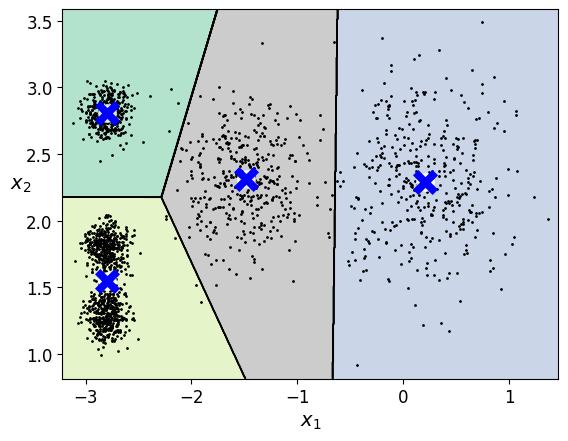

In [47]:
plot_decision_boundaries(kmeans_per_k[4-1], X)
plt.show()

***

### Mediante las siluetas

Lo primero será definir qué es eso de la silueta, y con calma, que no es de digestión rápida:

**Coeficiente de silueta**: es una medida que se aplica instancia a instancia del dataset una vez ya asociada a un clúster por el algoritmo. Se define (lee y escucha con tranquilidad) como:

$$(b - a)/\max(a, b)$$

donde $a$ es la distancia media a las otras instancias en el mismo clúster (es la _distancia media intra-clúster_), y $b$ es la _distancia media al clúster más cercano_, es decir, la distancia media a las instancias del siguiente clúster más cercano (definido como el que minimiza $b$, excluyendo el clúster de la propia instancia).

**El coeficiente de silueta puede variar entre -1 y +1: un coeficiente cercano a +1 significa que la instancia está bien dentro de su propio clúster y lejos de otros clústeres, mientras que un coeficiente cercano a 0 significa que está cerca de un límite de clúster, y finalmente un coeficiente cercano a -1 significa que la instancia puede haber sido asignada al clúster incorrecto.**

Ojo, nosotros vamos a trabajar con el promedio (es decir, la suma de todos los coeficientes de silueta dividida por el número de instancias del dataset), que también se denomina "silhouette_score" (que, siguiendo el razonamiento anterior, puede ir de -1 a +1: cuanto más positivo, mejor).

Veamos cómo se calcula a mano para una instancia cualquiera, por ejemplo, la primera del dataset, con el modelo de $k=5$ que entrenamos al principio:

In [48]:
from sklearn.metrics import silhouette_samples

instancia = X[0]
cluster_propio = kmeans.labels_[0]

# a: distancia media a las demás instancias de su propio cluster
mismo_cluster = X[kmeans.labels_ == cluster_propio]
a = np.linalg.norm(mismo_cluster - instancia, axis=1).sum() / (len(mismo_cluster) - 1) # Excluimos la distancia a sí misma (que es 0)

# b: distancia media a las instancias del cluster más cercano (distinto del suyo)
b = min(np.linalg.norm(X[kmeans.labels_ == c] - instancia, axis=1).mean() for c in range(k) if c != cluster_propio)

print(f"a = {a:.3f}, b = {b:.3f}, coeficiente de silueta = {(b - a) / max(a, b):.3f}")
print(f"Calculado con sklearn: {silhouette_samples(X, kmeans.labels_)[0]:.3f}")

a = 0.242, b = 0.314, coeficiente de silueta = 0.231
Calculado con sklearn: 0.231


Vamos a trazar el score de silueta como una función de $k$:

In [49]:
from sklearn.metrics import silhouette_score

In [50]:
silhouette_score(X, kmeans.labels_)

0.6495652979643829

Empleando la lista de modelos k-means con distintos valores de k que entrenamos antes, obtenemos el score de silueta para cada uno y lo pintamos:

In [51]:
silhouette_scores = [silhouette_score(X, model.labels_)
                     for model in kmeans_per_k[1:]]

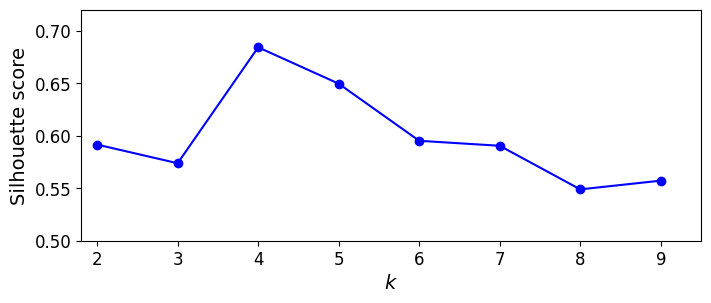

In [52]:
plt.figure(figsize=(8, 3))
plt.plot(range(2, 10), silhouette_scores, "bo-")
plt.xlabel("$k$", fontsize=14)
plt.ylabel("Silhouette score", fontsize=14)
plt.axis([1.8, 9.5, 0.5, 0.72])
plt.show()

Como puedes ver, esta visualización es mucho más rica que la anterior: en particular, aunque confirma que $k=4$ es una muy buena elección, también subraya el hecho de que $k=5$ es igualmente bueno.

Un diagrama de silueta proporciona una visualización aún más informativa cuando se traza el coeficiente de silueta de cada instancia, ordenados por el clúster al que están asignadas y por el valor del coeficiente. Esto se conoce como un _diagrama de silueta_:

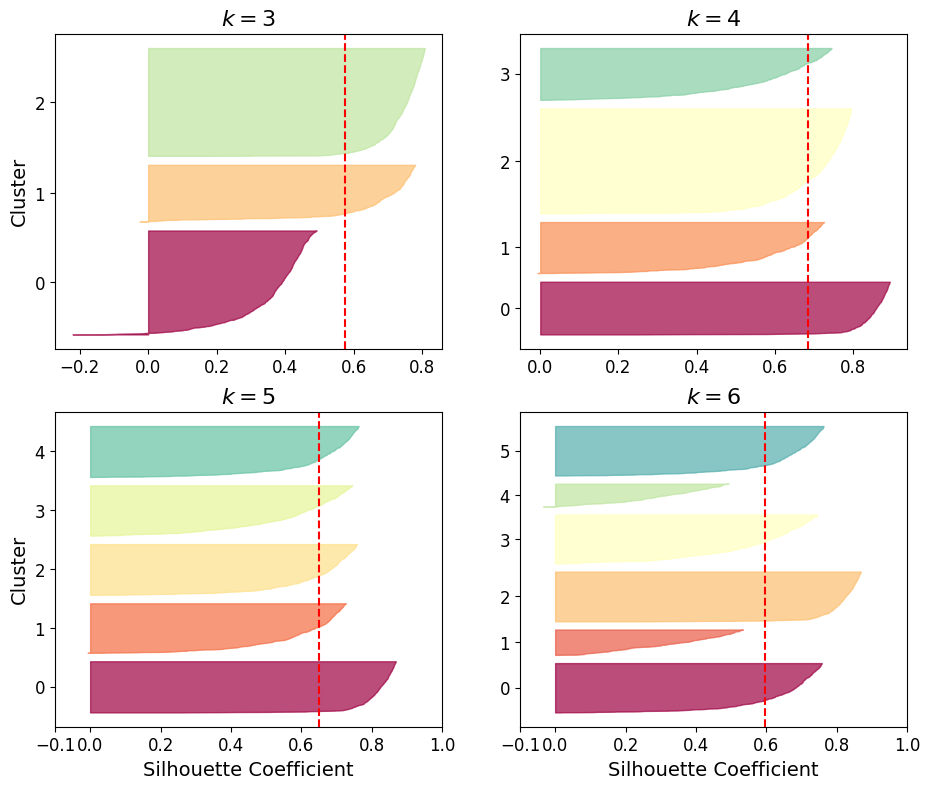

In [53]:
from sklearn.metrics import silhouette_samples
from matplotlib.ticker import FixedLocator, FixedFormatter

'''
La anchura de cada cuchillo representa el número de muestras por cluster. Están ordenadas
por su coeficiente de silueta, por eso tienen esa forma de cuchillo. Cuanta más caída tenga,
más disperso es el coeficiente de las muestras de ese cluster.
Deberían estar todos los clusters por encima de la media.
Hay algunas líneas hacia la izquierda porque el coeficiente es negativo: puntos asignados al cluster erróneo.
'''
plt.figure(figsize=(11, 9))

for k in (3, 4, 5, 6):
    plt.subplot(2, 2, k - 2)
    
    y_pred = kmeans_per_k[k - 1].labels_
    silhouette_coefficients = silhouette_samples(X, y_pred)

    padding = len(X) // 30
    pos = padding
    ticks = []
    for i in range(k):
        coeffs = silhouette_coefficients[y_pred == i]
        coeffs.sort()

        color = mpl.cm.Spectral(i / k)
        plt.fill_betweenx(np.arange(pos, pos + len(coeffs)), 0, coeffs,
                          facecolor=color, edgecolor=color, alpha=0.7)
        ticks.append(pos + len(coeffs) // 2)
        pos += len(coeffs) + padding

    plt.gca().yaxis.set_major_locator(FixedLocator(ticks))
    plt.gca().yaxis.set_major_formatter(FixedFormatter(range(k)))
    if k in (3, 5):
        plt.ylabel("Cluster")
    
    if k in (5, 6):
        plt.gca().set_xticks([-0.1, 0, 0.2, 0.4, 0.6, 0.8, 1])
        plt.xlabel("Silhouette Coefficient")
    else:
        plt.tick_params(labelbottom=True)

    plt.axvline(x=silhouette_scores[k - 2], color="red", linestyle="--")
    plt.title("$k={}$".format(k), fontsize=16)


plt.show()

En nuestro caso, observa que en $k=4$ y $k=5$, todos los "cuchillos" (los clusters) tienen instancias que superan el coeficiente medio (el score de silueta), pero no es el caso de $k=3$ y $k=6$, lo que refuerza que $k=4$ y $k=5$ son mejores valores.

### Límites de K-Means

Para terminar, veamos un caso en el que K-Means no funciona bien: tres grupos de formas alargadas (elípticas) y de tamaños distintos.

In [54]:
X1, y1 = make_blobs(n_samples=1000, centers=((4, -4), (0, 0)), random_state=42)
X1 = X1.dot(np.array([[0.374, 0.95], [0.732, 0.598]]))
X2, y2 = make_blobs(n_samples=250, centers=1, random_state=42)
X2 = X2 + [6, -8]
X = np.r_[X1, X2]
y = np.r_[y1, y2]

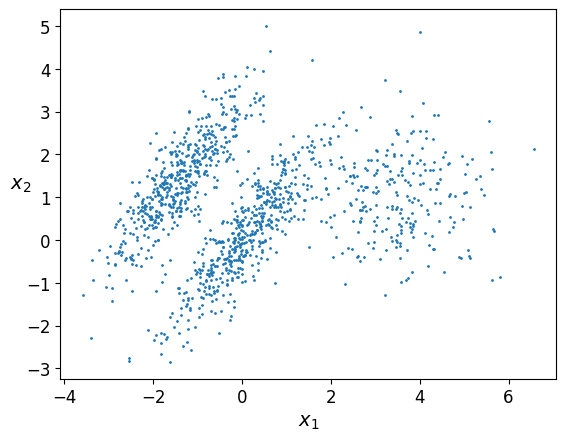

In [55]:
'''
Con algunas formas de clusters K-Means no se comporta muy bien. En
este ejemplo, una mejor agrupación tiene peor inercia.
'''
plot_clusters(X)

In [56]:
kmeans_good = KMeans(n_clusters = 3, 
                     init = np.array([[-1.5, 2.5], [0.5,0], [4,0]]), # Esta es la forma de darle nosotros los centroides
                     n_init = 1, 
                     random_state = 42)

kmeans_bad = KMeans(n_clusters = 3, random_state = 19)   

kmeans_good.fit(X)
kmeans_bad.fit(X)

,"n_clusters n_clusters: int, default=8The number of clusters to form as well as the number ofcentroids to generate.For an example of how to choose an optimal value for `n_clusters` refer to:ref:`sphx_glr_auto_examples_cluster_plot_kmeans_silhouette_analysis.py`.",3
,"random_state random_state: int, RandomState instance or None, default=NoneDetermines random number generation for centroid initialization. Usean int to make the randomness deterministic.See :term:`Glossary <random_state>`.",19
,"init init: {'k-means++', 'random'}, callable or array-like of shape (n_clusters, n_features), default='k-means++'Method for initialization:* 'k-means++' : selects initial cluster centroids using sampling based on an empirical probability distribution of the points' contribution to the overall inertia. This technique speeds up convergence. The algorithm implemented is ""greedy k-means++"". It differs from the vanilla k-means++ by making several trials at each sampling step and choosing the best centroid among them.* 'random': choose `n_clusters` observations (rows) at random from data for the initial centroids.* If an array is passed, it should be of shape (n_clusters, n_features) and gives the initial centers.* If a callable is passed, it should take arguments X, n_clusters and a random state and return an initialization.For an example of how to use the different `init` strategies, see:ref:`sphx_glr_auto_examples_cluster_plot_kmeans_digits.py`.For an evaluation of the impact of initialization, see the example:ref:`sphx_glr_auto_examples_cluster_plot_kmeans_stability_low_dim_dense.py`.",'k-means++'
,"n_init n_init: 'auto' or int, default='auto'Number of times the k-means algorithm is run with different centroidseeds. The final results is the best output of `n_init` consecutive runsin terms of inertia. Several runs are recommended for sparsehigh-dimensional problems (see :ref:`kmeans_sparse_high_dim`).When `n_init='auto'`, the number of runs depends on the value of init:10 if using `init='random'` or `init` is a callable;1 if using `init='k-means++'` or `init` is an array-like... versionadded:: 1.2 Added 'auto' option for `n_init`... versionchanged:: 1.4 Default value for `n_init` changed to `'auto'`.",'auto'
,"max_iter max_iter: int, default=300Maximum number of iterations of the k-means algorithm for asingle run.",300
,"tol tol: float, default=1e-4Relative tolerance with regards to Frobenius norm of the differencein the cluster centers of two consecutive iterations to declareconvergence.",0.0001
,"verbose verbose: int, default=0Verbosity mode.",0
,"copy_x copy_x: bool, default=TrueWhen pre-computing distances it is more numerically accurate to centerthe data first. If copy_x is True (default), then the original data isnot modified. If False, the original data is modified, and put backbefore the function returns, but small numerical differences may beintroduced by subtracting and then adding the data mean. Note that ifthe original data is not C-contiguous, a copy will be made even ifcopy_x is False. If the original data is sparse, but not in CSR format,a copy will be made even if copy_x is False.",True
,"algorithm algorithm: {""lloyd"", ""elkan""}, default=""lloyd""K-means algorithm to use. The classical EM-style algorithm is `""lloyd""`.The `""elkan""` variation can be more efficient on some datasets withwell-defined clusters, by using the triangle inequality. However it'smore memory intensive due to the allocation of an extra array of shape`(n_samples, n_clusters)`... versionchanged:: 0.18 Added Elkan algorithm.. versionchanged:: 1.1 Renamed ""full"" to ""lloyd"", and deprecated ""auto"" and ""full"". Changed ""auto"" to use ""lloyd"" instead of ""elkan"".",'lloyd'
Name,Type,Value
"cluster_centers_ cluster_centers_: ndarray of shape (n_clusters, n_features)Coordinates of cluster centers. If the algorithm stops before fullyconverging (see ``tol`` and ``max_iter``), these will not beconsistent with ``labels_``.","ndarray[float64](3, 2)","[

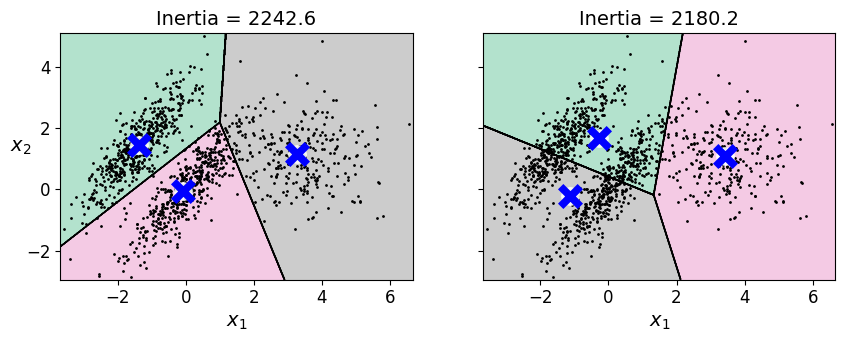

In [57]:
plt.figure(figsize=(10, 3.2))

plt.subplot(121)
plot_decision_boundaries(kmeans_good, X)
plt.title("Inertia = {:.1f}".format(kmeans_good.inertia_), fontsize=14)

plt.subplot(122)
plot_decision_boundaries(kmeans_bad, X, show_ylabels=False)
plt.title("Inertia = {:.1f}".format(kmeans_bad.inertia_), fontsize=14)


plt.show()

El modelo de la izquierda (al que hemos ayudado dándole nosotros los centroides iniciales) agrupa claramente mejor los datos y, sin embargo, tiene una inercia **mayor** que el de la derecha. K-Means asume grupos más o menos esféricos y de tamaño parecido; cuando no es así, minimizar la inercia no lleva a la mejor agrupación. Para estos casos tenemos otros algoritmos, como DBSCAN, que veremos en el siguiente notebook.